In [8]:
confusion_matrix_file_path = r"D:\NEW_TEST_DATA\Confusion_Matrix.txt"

# auto read in conf matrix

In [9]:
import numpy as np
import re

def read_conf_matrix(filename):
    """
    Reads the confusion matrix from a log file that contains metrics and
    'Conf_matrix (y_pred_matrix): [[ ... ]]'.
    Returns a NumPy 2D array.
    """
    with open(filename, "r") as f:
        text = f.read()

    # Find the confusion matrix block starting with 'Conf_matrix'
    match = re.search(r"Conf_matrix.*?(\[\[.*\]\])", text, flags=re.S)
    if not match:
        raise ValueError("No confusion matrix found in file.")

    matrix_str = match.group(1)

    # Remove brackets and split into rows
    rows = []
    for line in matrix_str.strip("[]").split("] ["):
        numbers = list(map(float, line.replace("[", "").replace("]", "").split()))
        rows.append(numbers)

    return np.array(rows)


In [22]:
conf_matrix = read_conf_matrix(confusion_matrix_file_path)
size = int(np.sqrt(conf_matrix.size))
conf_matrix = conf_matrix.reshape(size, size)
print(conf_matrix.shape)   # should be (25, 25)
print(conf_matrix[:2, :5]) # peek at first 2 rows, first 5 cols

(25, 25)
[[1.92e+09 1.19e+07 2.55e+07 1.24e+07 1.61e+07]
 [1.23e+04 2.30e+06 2.72e+04 1.47e+04 2.88e+04]]


# OR manually paste in conf matrix
(need to manually add commas too. it's slow even with multi cursors. Can be sped up with ctrl + right arrow which moves to next word, but the period and plus sign slow it down since it counts as a word. punctuation basically)

In [11]:
# Paste your confusion matrix here
conf_matrix = np.array([
 [1.92e+09, 1.19e+07, 2.55e+07, 1.24e+07, 1.61e+07, 3.39e+06, 2.66e+07, 1.45e+07, 1.06e+07, 7.68e+06, 1.47e+07, 2.11e+07, 2.80e+07, 8.19e+06, 1.15e+07, 8.85e+06, 1.26e+07, 1.25e+07, 4.30e+06, 1.15e+07, 1.38e+07, 2.79e+07, 3.03e+07, 2.57e+07, 2.71e+07],
 [1.23e+04, 2.30e+06, 2.72e+04, 1.47e+04, 2.88e+04, 1.05e+04, 4.38e+04, 1.79e+04, 9.36e+04, 1.02e+04, 1.74e+04, 3.31e+04, 3.03e+04, 1.36e+04, 1.78e+04, 2.35e+04, 8.89e+04, 2.65e+04, 5.88e+03, 1.48e+04, 4.01e+04, 3.33e+02, 2.41e+02, 4.72e+02, 7.49e+02],
 [6.55e+04, 7.09e+04, 5.10e+06, 5.48e+04, 5.88e+04, 1.33e+04, 9.31e+04, 8.38e+04, 1.04e+05, 5.19e+04, 3.45e+04, 6.60e+04, 3.01e+05, 2.74e+04, 5.21e+04, 3.56e+04, 6.78e+04, 5.18e+04, 1.62e+04, 1.09e+05, 4.08e+04, 3.03e+03, 2.82e+03, 4.12e+03, 4.43e+03],
 [1.42e+04, 1.40e+04, 2.44e+04, 2.07e+06, 3.35e+04, 6.18e+03, 2.71e+04, 6.09e+04, 2.97e+04, 2.54e+04, 1.85e+04, 3.81e+04, 2.89e+04, 5.96e+03, 7.11e+03, 1.91e+04, 3.69e+04, 5.59e+04, 3.77e+03, 7.90e+03, 9.87e+03, 4.64e+02, 3.45e+02, 6.09e+02, 8.98e+02],
 [2.45e+04, 3.33e+04, 2.75e+04, 3.95e+04, 2.23e+06, 1.05e+04, 1.27e+05, 1.91e+04, 6.11e+04, 8.24e+03, 1.20e+04, 1.86e+04, 2.60e+04, 8.83e+03, 1.12e+04, 1.55e+04, 8.68e+04, 3.68e+04, 4.26e+03, 1.11e+04, 1.35e+04, 3.37e+02, 2.25e+02, 6.66e+02, 6.09e+02],
 [1.26e+03, 4.72e+03, 2.68e+03, 2.42e+03, 4.97e+03, 5.55e+05, 2.96e+03, 9.81e+02, 5.08e+03, 1.05e+03, 2.48e+03, 4.83e+03, 1.36e+03, 6.80e+03, 2.00e+03, 1.24e+03, 6.61e+03, 5.58e+03, 8.28e+02, 1.73e+03, 5.19e+03, 9.10e+01, 1.10e+01, 5.60e+01, 1.16e+02],
 [5.95e+04, 6.85e+04, 5.30e+04, 4.08e+04, 1.40e+05, 1.00e+04, 3.30e+06, 6.07e+04, 6.00e+04, 1.29e+04, 2.82e+04, 6.30e+04, 1.43e+05, 2.59e+04, 1.95e+04, 2.62e+04, 6.13e+04, 6.30e+04, 7.00e+03, 1.90e+04, 3.50e+04, 2.52e+02, 1.96e+02, 7.25e+02, 6.01e+02],
 [1.71e+04, 1.64e+04, 3.72e+04, 5.11e+04, 1.61e+04, 3.42e+03, 4.53e+04, 2.17e+06, 2.76e+04, 2.84e+04, 1.07e+04, 4.45e+04, 7.69e+04, 1.82e+04, 1.24e+04, 1.05e+04, 1.74e+04, 1.00e+04, 2.88e+03, 8.25e+03, 8.82e+03, 3.30e+02, 2.63e+02, 6.25e+02, 7.34e+02],
 [7.22e+03, 5.19e+04, 2.32e+04, 1.50e+04, 2.59e+04, 8.63e+03, 1.99e+04, 1.41e+04, 1.63e+06, 1.09e+04, 1.01e+04, 1.59e+04, 1.91e+04, 9.75e+03, 1.31e+04, 1.52e+04, 3.34e+04, 1.68e+04, 4.34e+03, 1.02e+04, 1.19e+04, 4.27e+02, 3.17e+02, 5.12e+02, 5.92e+02],
 [5.43e+03, 7.29e+03, 2.57e+04, 2.41e+04, 5.81e+03, 2.72e+03, 5.63e+03, 3.45e+04, 1.60e+04, 1.58e+06, 4.72e+03, 9.86e+03, 7.85e+03, 2.54e+03, 2.69e+04, 9.48e+03, 1.11e+04, 6.90e+03, 4.87e+03, 2.30e+04, 4.29e+03, 6.74e+02, 6.96e+02, 7.43e+02, 1.05e+03],
 [1.56e+04, 3.27e+04, 2.64e+04, 3.26e+04, 2.19e+04, 1.06e+04, 3.64e+04, 2.15e+04, 3.55e+04, 1.21e+04, 3.19e+06, 2.16e+05, 2.64e+04, 2.19e+04, 4.41e+04, 2.62e+04, 2.16e+04, 3.50e+04, 7.19e+03, 2.15e+04, 1.54e+05, 3.21e+02, 1.01e+02, 3.18e+02, 5.31e+02],
 [2.55e+04, 7.39e+04, 5.53e+04, 5.99e+04, 4.12e+04, 2.04e+04, 8.98e+04, 8.44e+04, 7.14e+04, 2.64e+04, 1.78e+05, 4.82e+06, 7.27e+04, 7.54e+04, 8.16e+04, 3.74e+04, 4.75e+04, 5.53e+04, 1.20e+04, 3.15e+04, 9.06e+04, 2.79e+02, 1.59e+02, 4.39e+02, 1.06e+03],
 [8.67e+04, 7.83e+04, 2.60e+05, 5.95e+04, 5.63e+04, 1.05e+04, 2.24e+05, 1.39e+05, 9.10e+04, 2.31e+04, 3.53e+04, 7.74e+04, 4.34e+06, 4.22e+04, 2.99e+04, 4.07e+04, 6.84e+04, 5.83e+04, 8.11e+03, 3.67e+04, 4.64e+04, 1.43e+03, 1.48e+03, 3.04e+03, 2.85e+03],
 [5.92e+03, 9.48e+03, 8.21e+03, 3.05e+03, 5.28e+03, 5.84e+03, 1.51e+04, 1.64e+04, 1.09e+04, 1.81e+03, 8.91e+03, 3.78e+04, 1.92e+04, 1.25e+06, 1.44e+04, 3.41e+03, 5.20e+03, 3.33e+03, 1.45e+03, 3.52e+03, 4.46e+03, 2.15e+02, 6.50e+01, 2.17e+02, 2.96e+02],
 [8.88e+03, 2.08e+04, 2.92e+04, 8.76e+03, 1.26e+04, 6.06e+03, 1.44e+04, 1.66e+04, 2.83e+04, 2.82e+04, 2.83e+04, 4.85e+04, 1.48e+04, 2.31e+04, 2.75e+06, 1.29e+04, 1.67e+04, 1.17e+04, 1.02e+04, 7.21e+04, 1.60e+04, 7.88e+02, 1.31e+02, 3.20e+02, 6.36e+02],
 [8.18e+03, 3.03e+04, 1.62e+04, 2.24e+04, 1.47e+04, 3.77e+03, 1.94e+04, 1.01e+04, 3.33e+04, 1.44e+04, 1.56e+04, 1.53e+04, 1.99e+04, 6.22e+03, 1.19e+04, 1.97e+06, 3.24e+04, 3.12e+04, 6.34e+03, 1.18e+04, 3.59e+04, 5.67e+02, 2.81e+02, 5.90e+02, 1.13e+03],
 [1.21e+04, 8.77e+04, 2.81e+04, 3.15e+04, 5.94e+04, 1.38e+04, 3.84e+04, 1.74e+04, 6.48e+04, 1.38e+04, 1.20e+04, 2.27e+04, 2.92e+04, 9.41e+03, 1.39e+04, 2.38e+04, 2.10e+06, 8.36e+04, 6.06e+03, 1.35e+04, 1.67e+04, 4.24e+02, 3.57e+02, 6.91e+02, 8.65e+02],
 [1.24e+04, 3.20e+04, 2.60e+04, 5.54e+04, 3.48e+04, 1.17e+04, 4.69e+04, 1.24e+04, 3.74e+04, 1.08e+04, 2.11e+04, 3.08e+04, 3.10e+04, 7.82e+03, 1.24e+04, 2.60e+04, 1.08e+05, 2.32e+06, 4.78e+03, 1.23e+04, 9.04e+04, 3.31e+02, 2.56e+02, 5.98e+02, 8.93e+02],
 [1.83e+03, 4.06e+03, 5.62e+03, 1.69e+03, 2.09e+03, 1.31e+03, 2.41e+03, 1.52e+03, 4.78e+03, 6.42e+03, 3.69e+03, 2.68e+03, 1.66e+03, 1.35e+03, 1.08e+04, 4.88e+03, 3.51e+03, 2.62e+03, 9.73e+05, 2.01e+04, 2.79e+03, 4.67e+02, 4.60e+02, 2.27e+02, 3.76e+02],
 [9.98e+03, 1.85e+04, 7.35e+04, 9.41e+03, 1.31e+04, 5.63e+03, 1.51e+04, 1.16e+04, 2.44e+04, 3.03e+04, 1.49e+04, 1.61e+04, 2.06e+04, 7.55e+03, 9.18e+04, 1.31e+04, 1.70e+04, 1.16e+04, 1.86e+04, 2.59e+06, 1.41e+04, 9.51e+02, 3.85e+02, 4.94e+02, 7.48e+02],
 [1.52e+04, 8.00e+04, 3.12e+04, 1.96e+04, 2.60e+04, 1.68e+04, 4.33e+04, 1.84e+04, 4.30e+04, 1.21e+04, 1.47e+05, 8.58e+04, 3.64e+04, 1.57e+04, 2.57e+04, 4.35e+04, 3.16e+04, 1.60e+05, 7.97e+03, 2.07e+04, 3.29e+06, 3.24e+02, 1.71e+02, 3.77e+02, 7.50e+02],
 [6.29e+04, 9.42e+02, 5.30e+03, 1.16e+03, 6.04e+02, 1.60e+02, 5.40e+02, 1.08e+03, 2.37e+03, 1.42e+03, 3.45e+02, 2.31e+02, 2.70e+03, 6.17e+02, 1.14e+03, 1.18e+03, 1.44e+03, 6.86e+02, 8.00e+02, 1.43e+03, 3.39e+02, 8.82e+06, 5.41e+05, 3.25e+05, 4.12e+05],
 [8.36e+04, 7.60e+02, 5.76e+03, 1.26e+03, 5.95e+02, 1.97e+02, 4.99e+02, 9.36e+02, 2.38e+03, 1.50e+03, 2.20e+02, 3.45e+02, 2.90e+03, 4.72e+02, 4.69e+02, 1.21e+03, 1.46e+03, 7.54e+02, 1.16e+03, 1.04e+03, 2.64e+02, 8.79e+05, 1.07e+07, 5.02e+05, 4.81e+05],
 [5.90e+04, 4.38e+02, 4.35e+03, 9.70e+02, 5.27e+02, 1.17e+02, 3.72e+02, 8.83e+02, 1.61e+03, 1.06e+03, 1.66e+02, 2.25e+02, 2.29e+03, 5.17e+02, 2.98e+02, 9.05e+02, 1.16e+03, 5.50e+02, 2.11e+02, 8.79e+02, 1.79e+02, 2.56e+05, 2.71e+05, 7.34e+06, 4.76e+05],
 [6.16e+04, 7.31e+02, 4.74e+03, 1.14e+03, 4.84e+02, 1.71e+02, 4.18e+02, 7.70e+02, 1.91e+03, 1.19e+03, 2.34e+02, 4.37e+02, 2.52e+03, 5.69e+02, 7.85e+02, 8.58e+02, 1.17e+03, 8.87e+02, 4.15e+02, 8.82e+02, 3.13e+02, 2.94e+05, 2.13e+05, 3.75e+05, 6.72e+06],
])

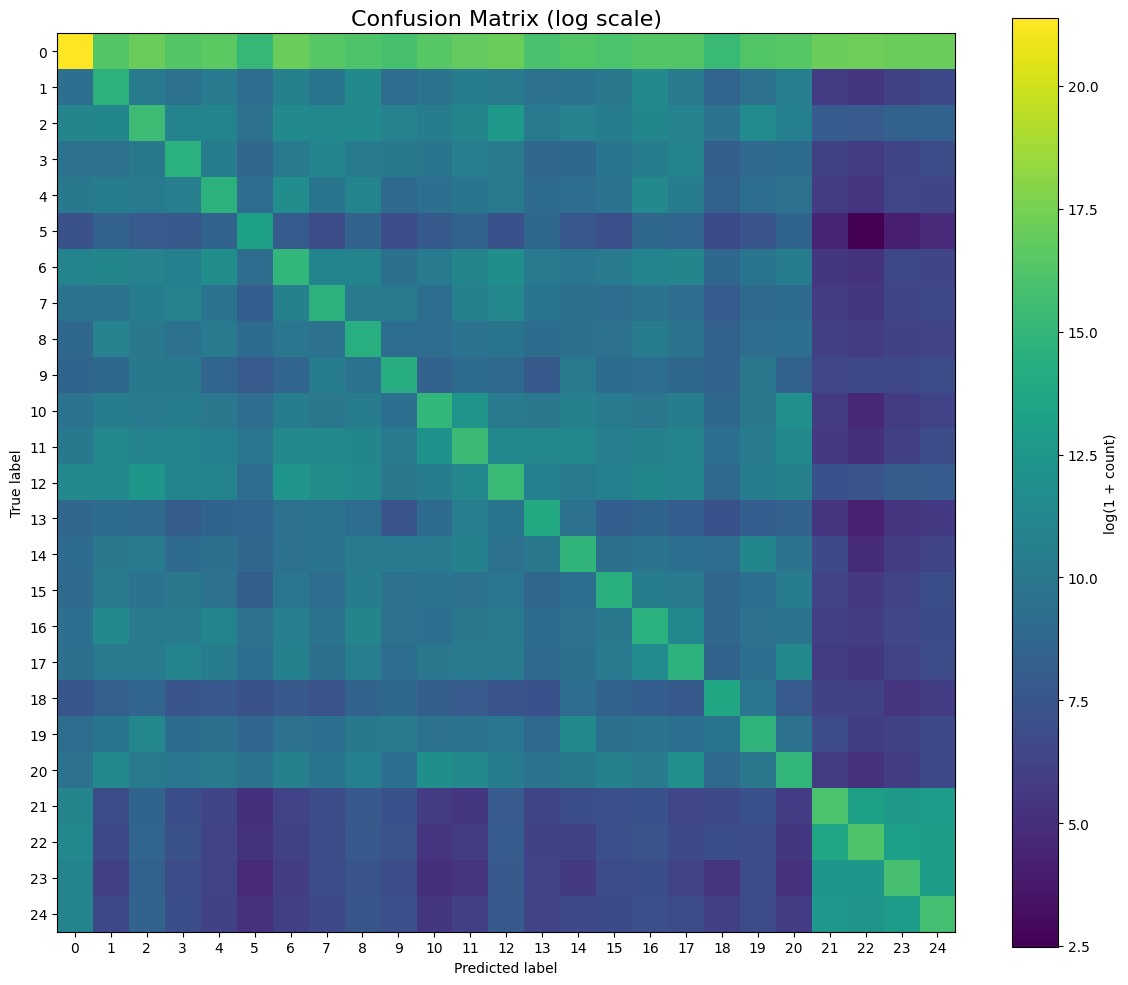

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# # Paste your confusion matrix here
# conf_matrix = np.array([
#  [1.92e+09, 1.19e+07, 2.55e+07, 1.24e+07, 1.61e+07, 3.39e+06, 2.66e+07, 1.45e+07, 1.06e+07, 7.68e+06, 1.47e+07, 2.11e+07, 2.80e+07, 8.19e+06, 1.15e+07, 8.85e+06, 1.26e+07, 1.25e+07, 4.30e+06, 1.15e+07, 1.38e+07, 2.79e+07, 3.03e+07, 2.57e+07, 2.71e+07],
#  [1.23e+04, 2.30e+06, 2.72e+04, 1.47e+04, 2.88e+04, 1.05e+04, 4.38e+04, 1.79e+04, 9.36e+04, 1.02e+04, 1.74e+04, 3.31e+04, 3.03e+04, 1.36e+04, 1.78e+04, 2.35e+04, 8.89e+04, 2.65e+04, 5.88e+03, 1.48e+04, 4.01e+04, 3.33e+02, 2.41e+02, 4.72e+02, 7.49e+02],
#  # ... continue with the rest of your rows ...
# ])

# Plot
plt.figure(figsize=(12, 10))
plt.imshow(np.log1p(conf_matrix), cmap="viridis")  # log scale for better contrast
plt.colorbar(label="log(1 + count)")

plt.title("Confusion Matrix (log scale)", fontsize=16)
plt.xlabel("Predicted label")
plt.ylabel("True label")

# Add ticks (25 classes)
num_classes = conf_matrix.shape[0]
plt.xticks(np.arange(num_classes))
plt.yticks(np.arange(num_classes))

plt.tight_layout()
plt.show()


# Row Normalization and Column Normalization

## straight scale

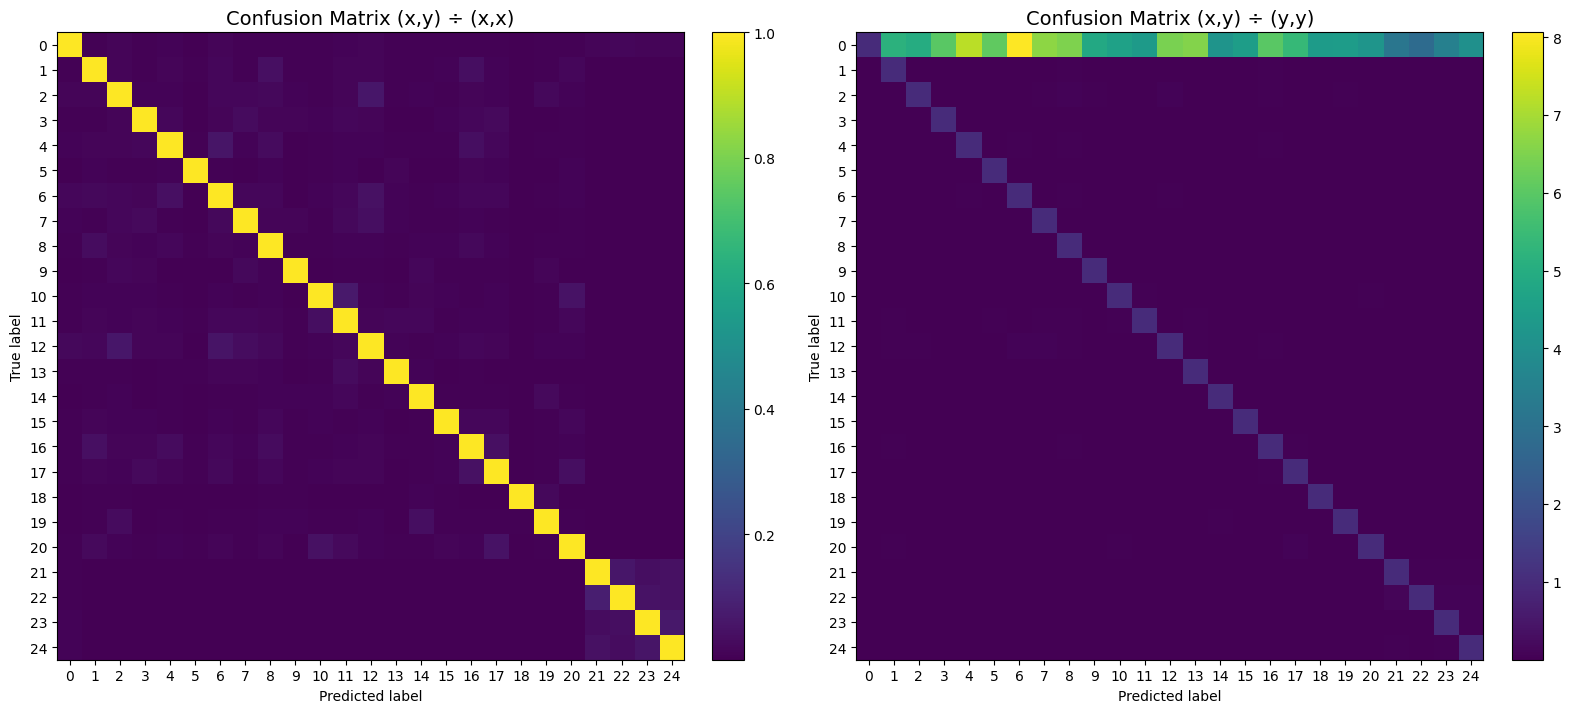

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# # Paste your confusion matrix here
# conf_matrix = np.array([
#  [1.92e+09, 1.19e+07, 2.55e+07, ...],
#  [1.23e+04, 2.30e+06, 2.72e+04, ...],
#  # ... continue with the rest of your rows ...
# ])

# Normalize by diagonal
norm_by_xx = conf_matrix / np.diag(conf_matrix)[:, None]   # divide by (x,x)
norm_by_yy = conf_matrix / np.diag(conf_matrix)[None, :]   # divide by (y,y)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# First figure: divide by (x,x)
im1 = axes[0].imshow(norm_by_xx, cmap="viridis")
axes[0].set_title("Confusion Matrix (x,y) ÷ (x,x)", fontsize=14)
axes[0].set_xlabel("Predicted label")
axes[0].set_ylabel("True label")
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

# Second figure: divide by (y,y)
im2 = axes[1].imshow(norm_by_yy, cmap="viridis")
axes[1].set_title("Confusion Matrix (x,y) ÷ (y,y)", fontsize=14)
axes[1].set_xlabel("Predicted label")
axes[1].set_ylabel("True label")
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

# Add ticks (assuming square matrix with N classes)
num_classes = conf_matrix.shape[0]
for ax in axes:
    ax.set_xticks(np.arange(num_classes))
    ax.set_yticks(np.arange(num_classes))

plt.tight_layout()
plt.show()


In [14]:
print("Diagonal:", np.diag(norm_by_xx))

Diagonal: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1.]


## log scale

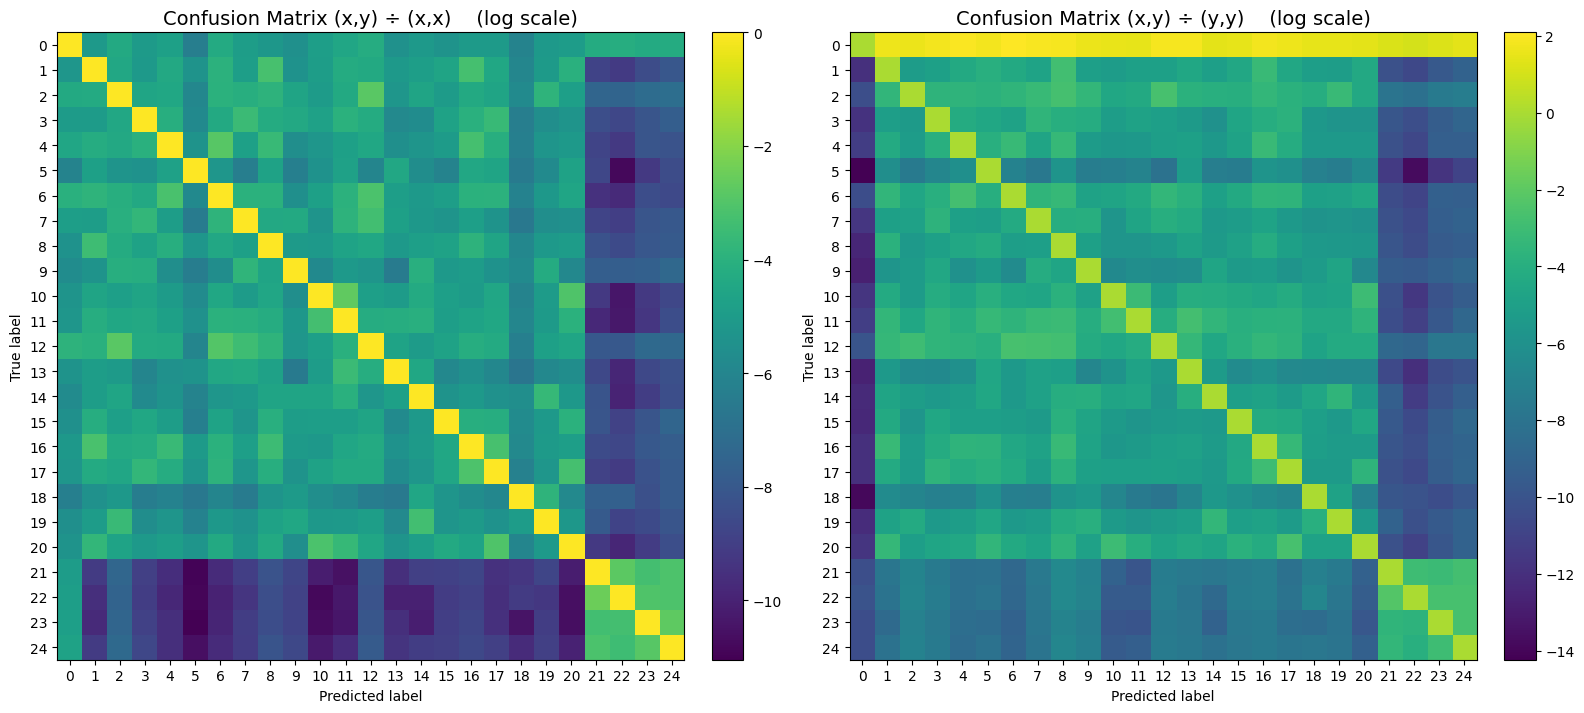

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# # Paste your confusion matrix here
# conf_matrix = np.array([
#  [1.92e+09, 1.19e+07, 2.55e+07, ...],
#  [1.23e+04, 2.30e+06, 2.72e+04, ...],
#  # ... continue with the rest of your rows ...
# ])

# Normalize by diagonal
norm_by_xx = conf_matrix / np.diag(conf_matrix)[:, None]   # divide by (x,x)
norm_by_yy = conf_matrix / np.diag(conf_matrix)[None, :]   # divide by (y,y)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# First figure: divide by (x,x)
im1 = axes[0].imshow(np.log(norm_by_xx), cmap="viridis")
axes[0].set_title("Confusion Matrix (x,y) ÷ (x,x)    (log scale)", fontsize=14)
axes[0].set_xlabel("Predicted label")
axes[0].set_ylabel("True label")
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

# Second figure: divide by (y,y)
im2 = axes[1].imshow(np.log(norm_by_yy), cmap="viridis")
axes[1].set_title("Confusion Matrix (x,y) ÷ (y,y)    (log scale)", fontsize=14)
axes[1].set_xlabel("Predicted label")
axes[1].set_ylabel("True label")
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

# Add ticks (assuming square matrix with N classes)
num_classes = conf_matrix.shape[0]
for ax in axes:
    ax.set_xticks(np.arange(num_classes))
    ax.set_yticks(np.arange(num_classes))

plt.tight_layout()
plt.show()


# DONT use. just for verifying the broadcasting version is same as for loop version (well duh should be)

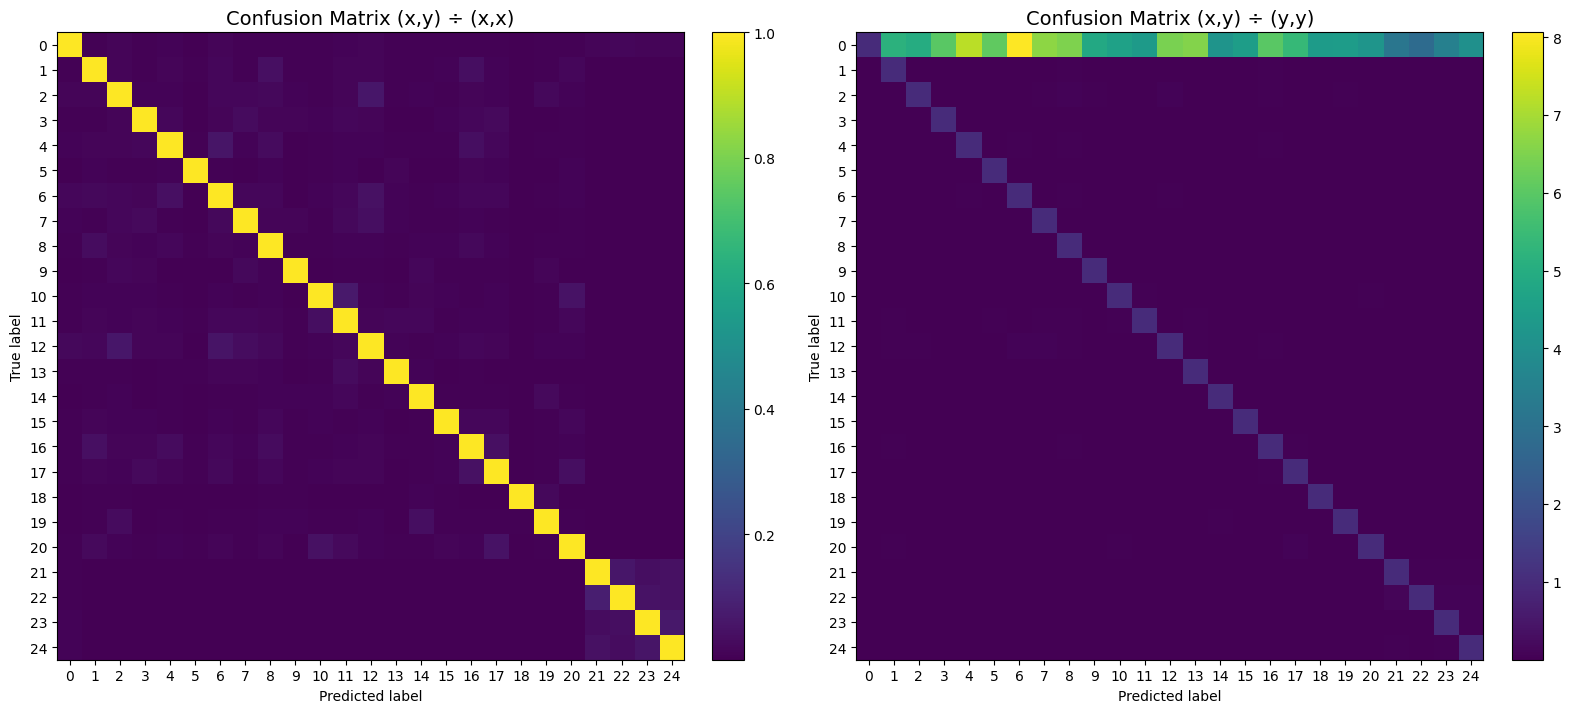

In [16]:
import numpy as np

# conf_matrix = np.array([
#     [50,  2,  3],
#     [ 4, 45,  1],
#     [ 5,  2, 40]
# ])

N = conf_matrix.shape[0]

# --- Row normalization (each row divided by its diagonal element) ---
norm_by_xx_loop = np.zeros_like(conf_matrix, dtype=float)
for i in range(N):
    if conf_matrix[i, i] != 0:
        norm_by_xx_loop[i, :] = conf_matrix[i, :] / conf_matrix[i, i]
    else:
        norm_by_xx_loop[i, :] = conf_matrix[i, :]  # avoid divide by zero

# --- Column normalization (each col divided by its diagonal element) ---
norm_by_yy_loop = np.zeros_like(conf_matrix, dtype=float)
for j in range(N):
    if conf_matrix[j, j] != 0:
        norm_by_yy_loop[:, j] = conf_matrix[:, j] / conf_matrix[j, j]
    else:
        norm_by_yy_loop[:, j] = conf_matrix[:, j]

# print("Row-normalized (loop):\n", norm_by_xx_loop)
# print("\nCol-normalized (loop):\n", norm_by_yy_loop)


fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# First figure: divide by (x,x)
im1 = axes[0].imshow(norm_by_xx, cmap="viridis")
axes[0].set_title("Confusion Matrix (x,y) ÷ (x,x)", fontsize=14)
axes[0].set_xlabel("Predicted label")
axes[0].set_ylabel("True label")
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

# Second figure: divide by (y,y)
im2 = axes[1].imshow(norm_by_yy, cmap="viridis")
axes[1].set_title("Confusion Matrix (x,y) ÷ (y,y)", fontsize=14)
axes[1].set_xlabel("Predicted label")
axes[1].set_ylabel("True label")
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

# Add ticks (assuming square matrix with N classes)
num_classes = conf_matrix.shape[0]
for ax in axes:
    ax.set_xticks(np.arange(num_classes))
    ax.set_yticks(np.arange(num_classes))

plt.tight_layout()
plt.show()


# 9_25_25

using a custom order (ie doing it by hand)

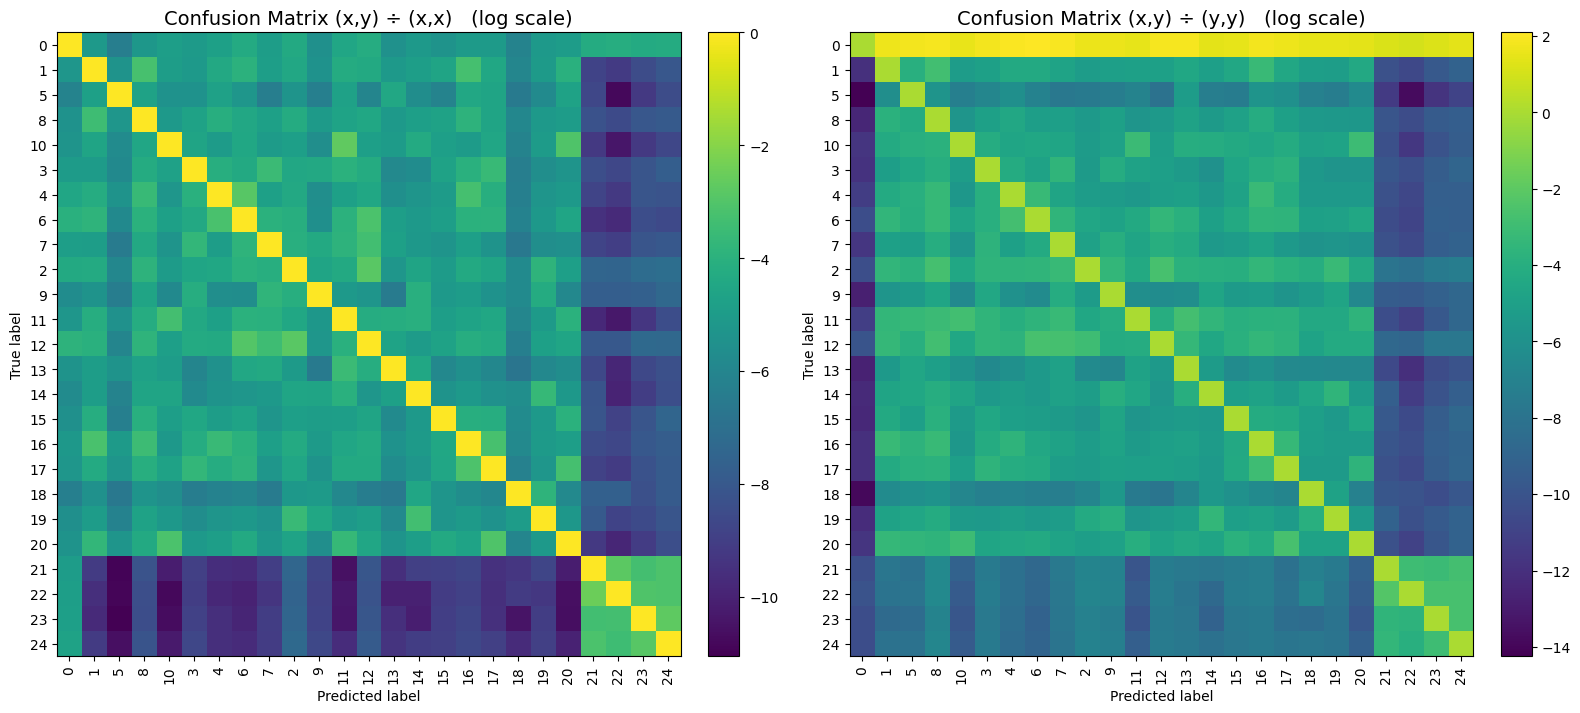

In [35]:
import numpy as np
import matplotlib.pyplot as plt

# Example confusion matrix (20x20 for demonstration)
np.random.seed(0)
# conf_matrix = np.random.randint(1, 1000, size=(20, 20))  # nonzero to avoid log(0)

# Example manual grouping order
order = [0, 1, 5, 8, 10,
         3, 4, 6, 7,
         2, 9, 11,
         12, 13, 14,
         15, 16, 17,
         18, 19, 20,
         21, 22, 23, 24]

# Reorder rows and cols
conf_matrix_ordered = conf_matrix[np.ix_(order, order)]

# Normalize by diagonal (after reordering)
norm_by_xx = conf_matrix_ordered / np.diag(conf_matrix_ordered)[:, None]
norm_by_yy = conf_matrix_ordered / np.diag(conf_matrix_ordered)[None, :]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Row normalization (÷ (x,x))
im1 = axes[0].imshow(np.log(norm_by_xx), cmap="viridis")
axes[0].set_title("Confusion Matrix (x,y) ÷ (x,x)   (log scale)", fontsize=14)
axes[0].set_xlabel("Predicted label")
axes[0].set_ylabel("True label")
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

# Column normalization (÷ (y,y))
im2 = axes[1].imshow(np.log(norm_by_yy), cmap="viridis")
axes[1].set_title("Confusion Matrix (x,y) ÷ (y,y)   (log scale)", fontsize=14)
axes[1].set_xlabel("Predicted label")
axes[1].set_ylabel("True label")
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

# Add ticks (with reordered indices)
num_classes = conf_matrix_ordered.shape[0]
for ax in axes:
    ax.set_xticks(np.arange(num_classes))
    ax.set_yticks(np.arange(num_classes))
    ax.set_xticklabels(order, rotation=90)
    ax.set_yticklabels(order)

plt.tight_layout()
plt.show()


clustering

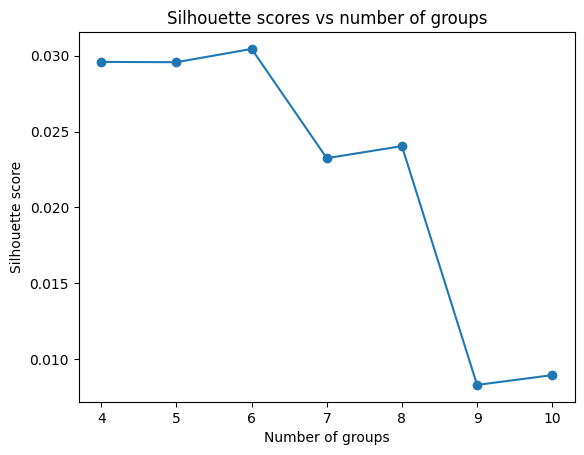

Suggested number of groups: 6
Class -> Group mapping:
Class 1 -> Group 0
Class 2 -> Group 0
Class 3 -> Group 0
Class 4 -> Group 0
Class 5 -> Group 5
Class 6 -> Group 0
Class 7 -> Group 0
Class 8 -> Group 0
Class 9 -> Group 2
Class 10 -> Group 0
Class 11 -> Group 0
Class 12 -> Group 0
Class 13 -> Group 4
Class 14 -> Group 1
Class 15 -> Group 0
Class 16 -> Group 0
Class 17 -> Group 0
Class 18 -> Group 3
Class 19 -> Group 1
Class 20 -> Group 0


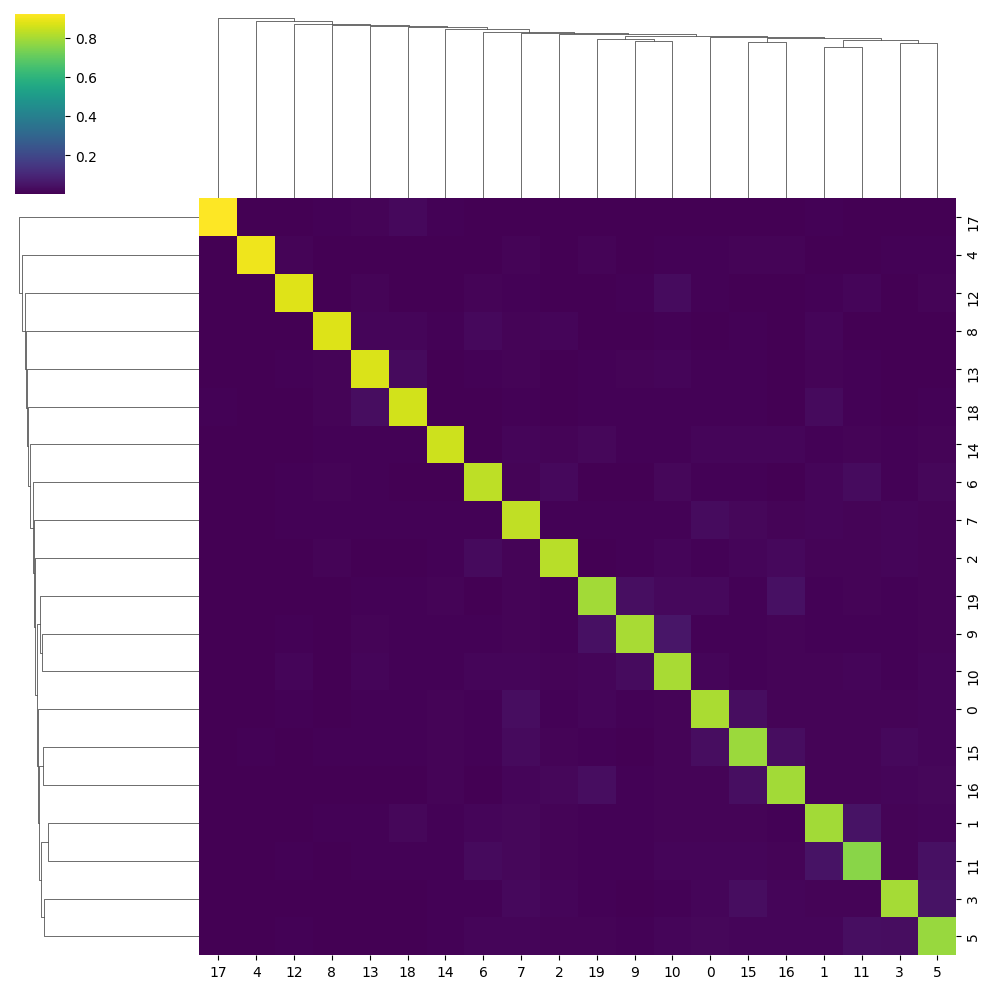

In [42]:
import numpy as np
from sklearn.preprocessing import normalize
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

# Example: your Conf_matrix (replace with actual matrix)
# conf_matrix = np.array([...])  # your 25x25 matrix

# Step 1: extract main classes (exclude first baseline and last 4 optional)
main_conf = conf_matrix[1:21, 1:21]

# Step 2: normalize rows to sum to 1 (optional, for clustering)
main_conf_norm = normalize(main_conf, norm='l1', axis=1)

# Step 3: try hierarchical clustering with different numbers of groups
sil_scores = []
range_k = range(4, 11)  # try 4 to 10 groups

for k in range_k:
    clustering = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward')
    labels = clustering.fit_predict(main_conf_norm)
    score = silhouette_score(main_conf_norm, labels)
    sil_scores.append(score)

# Step 4: plot silhouette scores to choose optimal k
plt.figure()
plt.plot(range_k, sil_scores, marker='o')
plt.xlabel('Number of groups')
plt.ylabel('Silhouette score')
plt.title('Silhouette scores vs number of groups')
plt.show()

# Step 5: choose best k (highest silhouette score)
best_k = range_k[np.argmax(sil_scores)]
print("Suggested number of groups:", best_k)

# Step 6: final clustering with best_k
final_clustering = AgglomerativeClustering(n_clusters=best_k, metric='euclidean', linkage='ward')
final_labels = final_clustering.fit_predict(main_conf_norm)
print("Class -> Group mapping:")
for cls, grp in enumerate(final_labels, start=1):
    print(f"Class {cls} -> Group {grp}")

# Optional: visualize heatmap with clustered rows/columns
sns.clustermap(main_conf_norm, row_cluster=True, col_cluster=True, cmap='viridis')
plt.show()


clustering + logscale

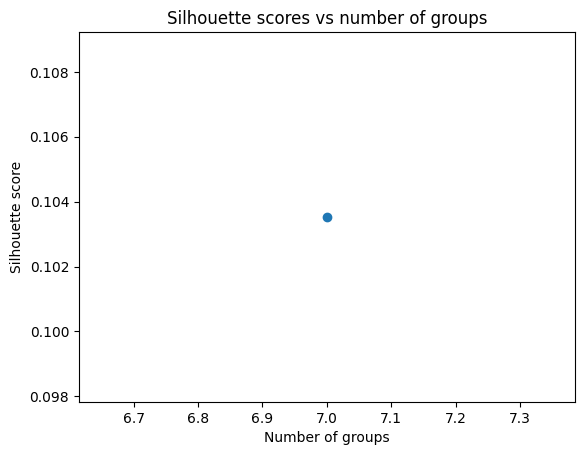

Suggested number of groups: 7

Class -> Group mapping:
Class 1 -> Group 1
Class 2 -> Group 6
Class 3 -> Group 6
Class 4 -> Group 1
Class 5 -> Group 5
Class 6 -> Group 1
Class 7 -> Group 6
Class 8 -> Group 1
Class 9 -> Group 2
Class 10 -> Group 0
Class 11 -> Group 0
Class 12 -> Group 6
Class 13 -> Group 3
Class 14 -> Group 2
Class 15 -> Group 0
Class 16 -> Group 1
Class 17 -> Group 0
Class 18 -> Group 4
Class 19 -> Group 2
Class 20 -> Group 0


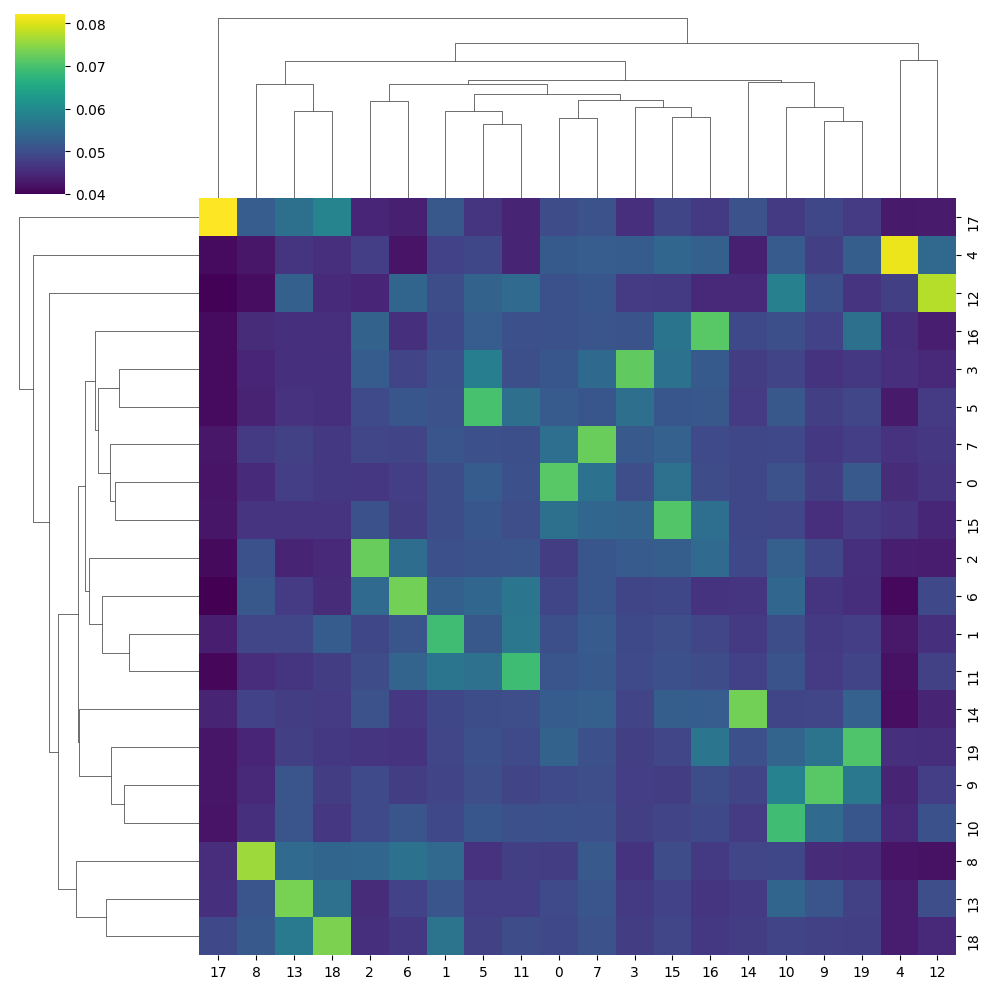

In [79]:
import numpy as np
from sklearn.preprocessing import normalize
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

# Replace this with your full 25x25 confidence matrix
# conf_matrix = np.array([...])  # your 25x25 matrix here

# ----------------- Step 1: Extract main 20 classes -----------------
# Exclude first baseline row/column and last 4 optional baselines
main_conf = conf_matrix[1:21, 1:21]  # shape (20, 20)

# ----------------- Step 2: Preprocess -----------------
# Optional: log-transform to reduce dynamic range
main_conf_log = np.log1p(main_conf)

# Row-wise normalization so each class vector sums to 1
main_conf_norm = normalize(main_conf_log, norm='l1', axis=1)

# ----------------- Step 3: Try different numbers of clusters -----------------
sil_scores = []
range_k = range(7, 8)  # test 4 to 10 groups

for k in range_k:
    clustering = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward')
    labels = clustering.fit_predict(main_conf_norm)
    score = silhouette_score(main_conf_norm, labels)
    sil_scores.append(score)

# ----------------- Step 4: Plot silhouette scores -----------------
plt.figure()
plt.plot(range_k, sil_scores, marker='o')
plt.xlabel('Number of groups')
plt.ylabel('Silhouette score')
plt.title('Silhouette scores vs number of groups')
plt.show()

# ----------------- Step 5: Final clustering -----------------
best_k = range_k[np.argmax(sil_scores)]
print("Suggested number of groups:", best_k)

final_clustering = AgglomerativeClustering(n_clusters=best_k, metric='euclidean', linkage='ward')
final_labels = final_clustering.fit_predict(main_conf_norm)

print("\nClass -> Group mapping:")
for cls, grp in enumerate(final_labels, start=1):  # Classes 1 to 20
    print(f"Class {cls} -> Group {grp}")

# ----------------- Step 6: Optional heatmap -----------------
sns.clustermap(main_conf_norm, row_cluster=True, col_cluster=True, cmap='viridis')
plt.show()


change metric to cosine or correlation

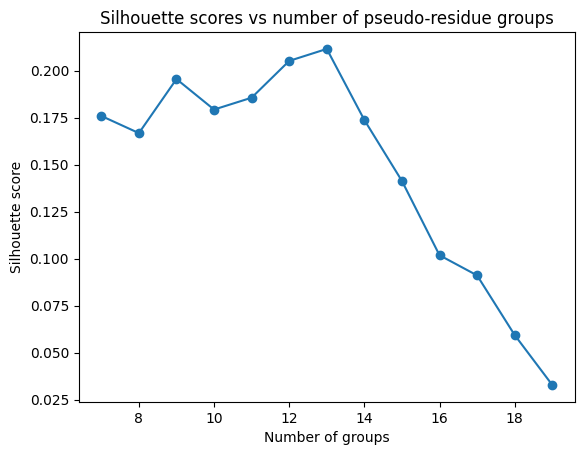

Suggested number of groups: 13

Residue -> pseudo-group mapping:
Residue 1 -> Group 2
Residue 2 -> Group 3
Residue 3 -> Group 9
Residue 4 -> Group 5
Residue 5 -> Group 11
Residue 6 -> Group 5
Residue 7 -> Group 12
Residue 8 -> Group 2
Residue 9 -> Group 6
Residue 10 -> Group 4
Residue 11 -> Group 4
Residue 12 -> Group 3
Residue 13 -> Group 7
Residue 14 -> Group 0
Residue 15 -> Group 8
Residue 16 -> Group 2
Residue 17 -> Group 1
Residue 18 -> Group 10
Residue 19 -> Group 0
Residue 20 -> Group 1


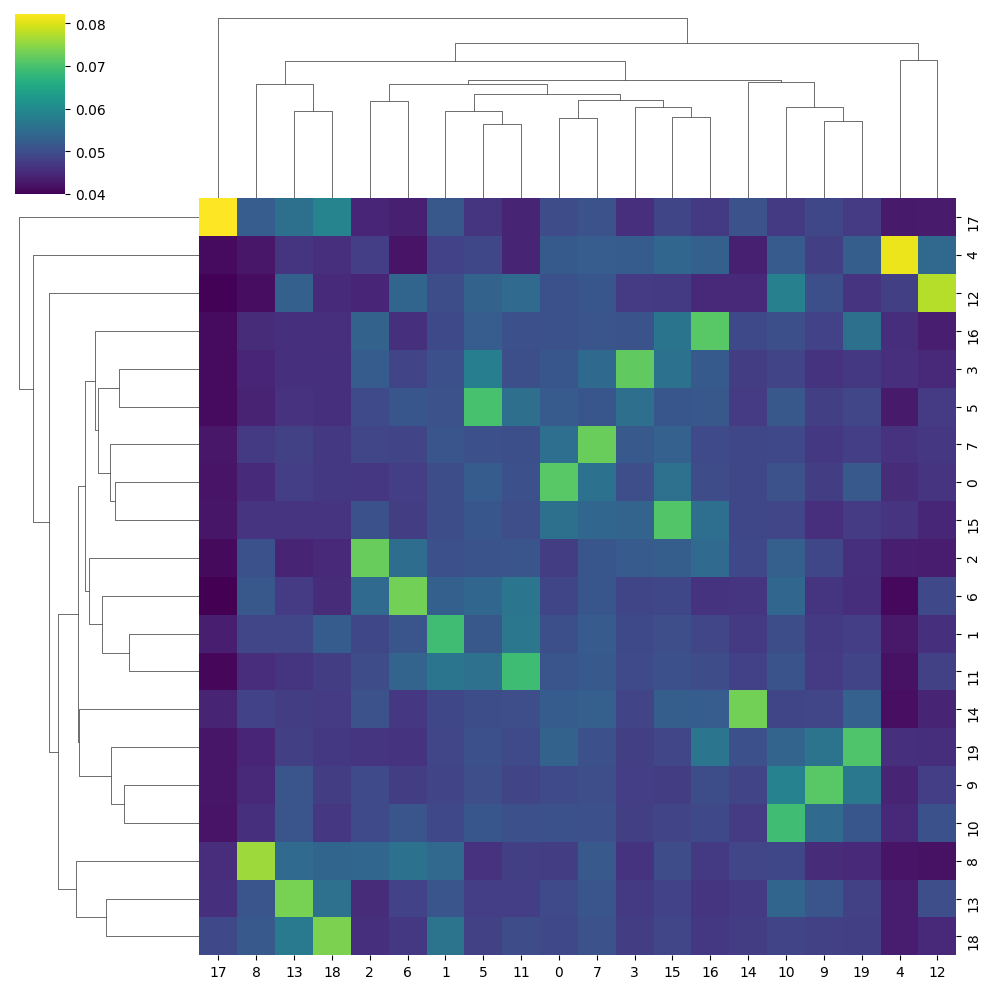

In [83]:
import numpy as np
from sklearn.preprocessing import normalize
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import pdist, squareform
import matplotlib.pyplot as plt
import seaborn as sns

# Step 0: conf_matrix = your 25x25 matrix
main_conf = conf_matrix[1:21, 1:21]

# Optional: log-transform to reduce large magnitude differences
main_conf_log = np.log1p(main_conf)

# Normalize rows so each row sums to 1
main_conf_norm = normalize(main_conf_log, axis=1, norm='l1')

# ----------------- Step 1: compute distance matrix -----------------
# Using correlation distance
dist_matrix = squareform(pdist(main_conf_norm, metric='cosine'))   # use 'cosine' or 'correlation'

# ----------------- Step 2: silhouette analysis for range of clusters -----------------
sil_scores = []
range_k = range(7, 20)

for k in range_k:
    clustering = AgglomerativeClustering(n_clusters=k, metric='precomputed', linkage='average')
    labels = clustering.fit_predict(dist_matrix)
    score = silhouette_score(dist_matrix, labels, metric='precomputed')
    sil_scores.append(score)

# Plot silhouette scores
plt.figure()
plt.plot(range_k, sil_scores, marker='o')
plt.xlabel('Number of groups')
plt.ylabel('Silhouette score')
plt.title('Silhouette scores vs number of pseudo-residue groups')
plt.show()

# ----------------- Step 3: final clustering with best k -----------------
best_k = range_k[np.argmax(sil_scores)]
print("Suggested number of groups:", best_k)

final_clustering = AgglomerativeClustering(n_clusters=best_k, metric='precomputed', linkage='average')
final_labels = final_clustering.fit_predict(dist_matrix)

print("\nResidue -> pseudo-group mapping:")
for cls, grp in enumerate(final_labels, start=1):
    print(f"Residue {cls} -> Group {grp}")

# Optional: clustered heatmap for visualization
sns.clustermap(main_conf_norm, row_cluster=True, col_cluster=True, cmap='viridis')
plt.show()


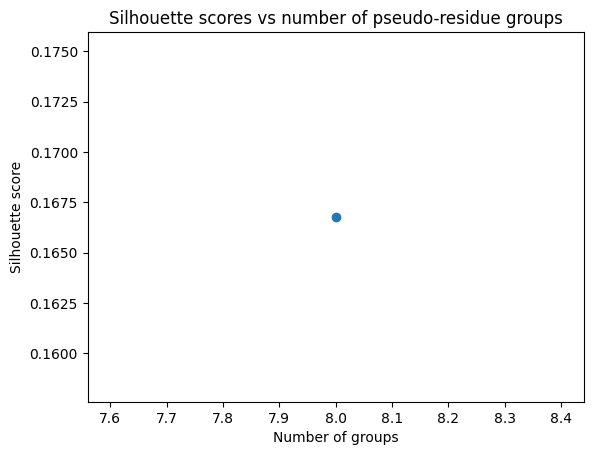

Suggested number of groups: 8

Residue -> pseudo-group mapping:
Residue 1 -> Group 0
Residue 2 -> Group 0
Residue 3 -> Group 0
Residue 4 -> Group 0
Residue 5 -> Group 5
Residue 6 -> Group 0
Residue 7 -> Group 0
Residue 8 -> Group 0
Residue 9 -> Group 6
Residue 10 -> Group 2
Residue 11 -> Group 2
Residue 12 -> Group 0
Residue 13 -> Group 7
Residue 14 -> Group 1
Residue 15 -> Group 3
Residue 16 -> Group 0
Residue 17 -> Group 2
Residue 18 -> Group 4
Residue 19 -> Group 1
Residue 20 -> Group 2

Group -> residues mapping:
Group 0: [1, 2, 3, 4, 6, 7, 8, 12, 16]
Group 5: [5]
Group 6: [9]
Group 2: [10, 11, 17, 20]
Group 7: [13]
Group 1: [14, 19]
Group 3: [15]
Group 4: [18]


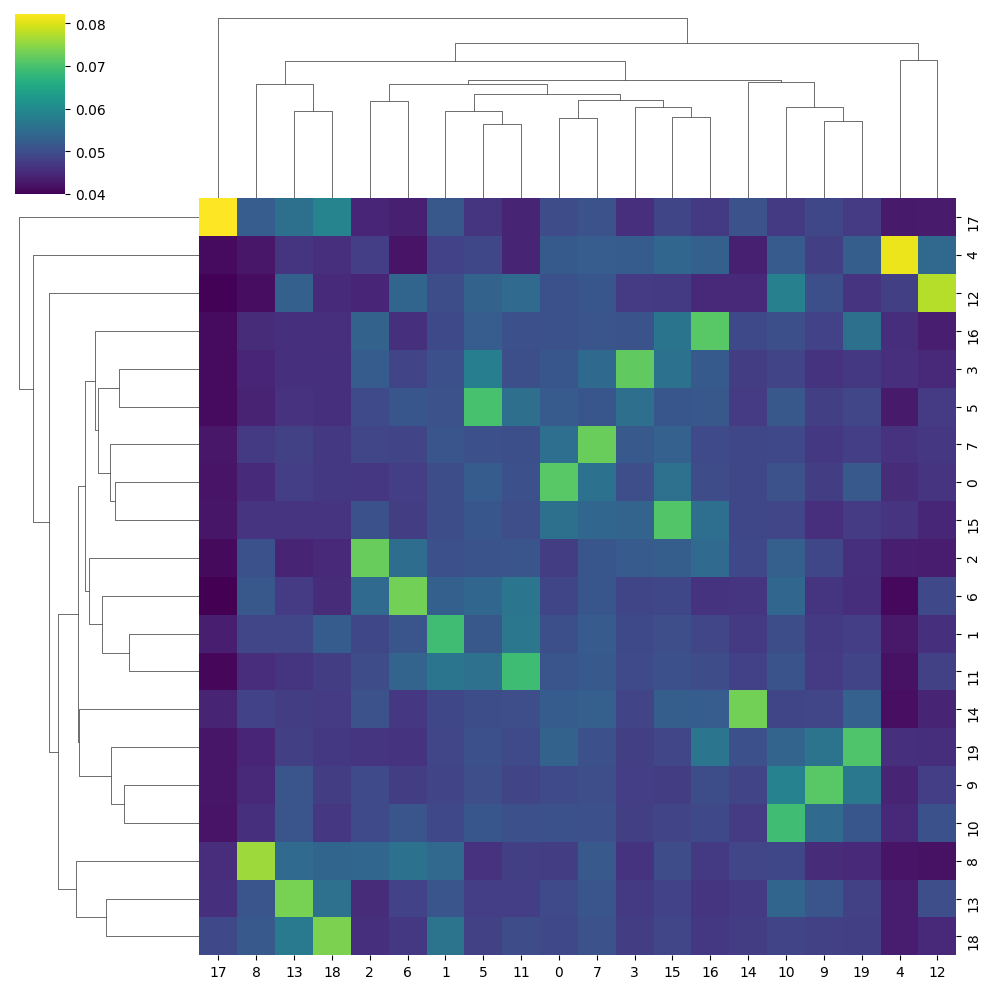

In [90]:
import numpy as np
from sklearn.preprocessing import normalize
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import pdist, squareform
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict

# Step 0: conf_matrix = your 25x25 matrix
main_conf = conf_matrix[1:21, 1:21]

# Optional: log-transform to reduce large magnitude differences
main_conf_log = np.log1p(main_conf)

# Normalize rows so each row sums to 1
main_conf_norm = normalize(main_conf_log, axis=1, norm='l1')

# ----------------- Step 1: compute distance matrix -----------------
# Using correlation distance
dist_matrix = squareform(pdist(main_conf_norm, metric='cosine'))   # use 'cosine' or 'correlation'

# ----------------- Step 2: silhouette analysis for range of clusters -----------------
sil_scores = []
range_k = range(8, 9)

for k in range_k:
    clustering = AgglomerativeClustering(n_clusters=k, metric='precomputed', linkage='average')
    labels = clustering.fit_predict(dist_matrix)
    score = silhouette_score(dist_matrix, labels, metric='precomputed')
    sil_scores.append(score)

# Plot silhouette scores
plt.figure()
plt.plot(range_k, sil_scores, marker='o')
plt.xlabel('Number of groups')
plt.ylabel('Silhouette score')
plt.title('Silhouette scores vs number of pseudo-residue groups')
plt.show()

# ----------------- Step 3: final clustering with best k -----------------
best_k = range_k[np.argmax(sil_scores)]
print("Suggested number of groups:", best_k)

final_clustering = AgglomerativeClustering(n_clusters=best_k, metric='precomputed', linkage='average')
final_labels = final_clustering.fit_predict(dist_matrix)

print("\nResidue -> pseudo-group mapping:")
for res_idx, grp in enumerate(final_labels, start=1):
    print(f"Residue {res_idx} -> Group {grp}")

# ----------------- Step 4: invert mapping -----------------
groups = defaultdict(list)
for res_idx, grp in enumerate(final_labels, start=1):
    groups[grp].append(res_idx)

print("\nGroup -> residues mapping:")
for grp, residues in groups.items():
    print(f"Group {grp}: {residues}")

# Optional: clustered heatmap for visualization
sns.clustermap(main_conf_norm, row_cluster=True, col_cluster=True, cmap='viridis')
plt.show()


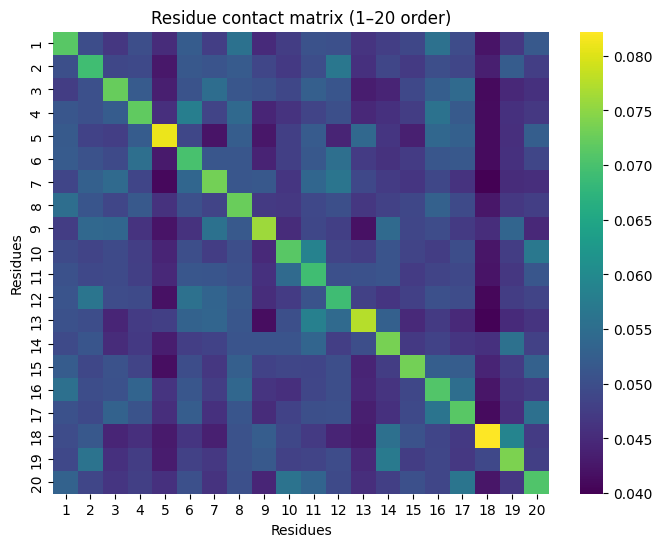

In [92]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    main_conf_norm,
    cmap="viridis",
    xticklabels=range(1, 21),
    yticklabels=range(1, 21),
    cbar=True
)
plt.title("Residue contact matrix (1–20 order)")
plt.xlabel("Residues")
plt.ylabel("Residues")
plt.show()


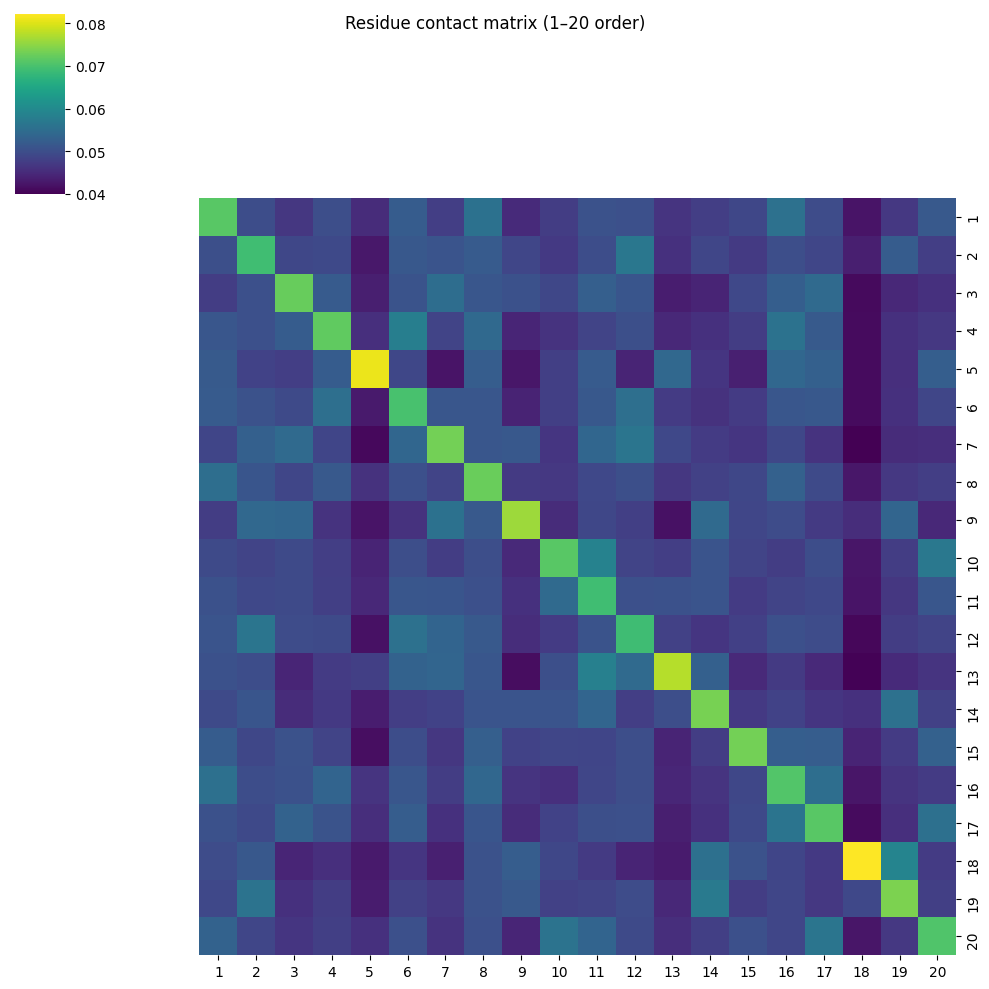

In [98]:
sns.clustermap(
    main_conf_norm,
    cmap="viridis",
    row_cluster=False,   # 🚫 no row clustering
    col_cluster=False,   # 🚫 no col clustering
    xticklabels=range(1, 21),
    yticklabels=range(1, 21)
)
plt.suptitle("Residue contact matrix (1–20 order)")
plt.show()


In [91]:
from collections import defaultdict

# Residues 1–20
residues_protein = [
    'ALA', 'ARG', 'ASN', 'ASP', 'CYS', 'GLU', 'GLN', 'GLY', 'HIS', 'ILE',
    'LEU', 'LYS', 'MET', 'PHE', 'PRO', 'SER', 'THR', 'TRP', 'TYR', 'VAL'
]

# ----------------- Step 3: final clustering with best k -----------------
best_k = range_k[np.argmax(sil_scores)]
print("Suggested number of groups:", best_k)

final_clustering = AgglomerativeClustering(
    n_clusters=best_k, metric='precomputed', linkage='average'
)
final_labels = final_clustering.fit_predict(dist_matrix)

print("\nResidue -> pseudo-group mapping:")
for res_idx, grp in enumerate(final_labels, start=1):
    res_name = residues_protein[res_idx - 1]
    print(f"{res_name} (Residue {res_idx}) -> Group {grp}")

# ----------------- Step 4: invert mapping -----------------
groups = defaultdict(list)
for res_idx, grp in enumerate(final_labels, start=1):
    res_name = residues_protein[res_idx - 1]
    groups[grp].append(res_name)

print("\nGroup -> residues mapping:")
for grp, residues in groups.items():
    print(f"Group {grp}: {', '.join(residues)}")


Suggested number of groups: 8

Residue -> pseudo-group mapping:
ALA (Residue 1) -> Group 0
ARG (Residue 2) -> Group 0
ASN (Residue 3) -> Group 0
ASP (Residue 4) -> Group 0
CYS (Residue 5) -> Group 5
GLU (Residue 6) -> Group 0
GLN (Residue 7) -> Group 0
GLY (Residue 8) -> Group 0
HIS (Residue 9) -> Group 6
ILE (Residue 10) -> Group 2
LEU (Residue 11) -> Group 2
LYS (Residue 12) -> Group 0
MET (Residue 13) -> Group 7
PHE (Residue 14) -> Group 1
PRO (Residue 15) -> Group 3
SER (Residue 16) -> Group 0
THR (Residue 17) -> Group 2
TRP (Residue 18) -> Group 4
TYR (Residue 19) -> Group 1
VAL (Residue 20) -> Group 2

Group -> residues mapping:
Group 0: ALA, ARG, ASN, ASP, GLU, GLN, GLY, LYS, SER
Group 5: CYS
Group 6: HIS
Group 2: ILE, LEU, THR, VAL
Group 7: MET
Group 1: PHE, TYR
Group 3: PRO
Group 4: TRP


1. keep lower triangle and reflect it upwards

Suggested number of groups: 13

Group -> residues mapping (lower triangle reflected):
Group 1: ALA, GLY
Group 2: ARG, LYS
Group 9: ASN
Group 4: ASP, GLU
Group 10: CYS
Group 11: GLN
Group 7: HIS
Group 0: ILE, LEU, VAL
Group 12: MET
Group 3: PHE, TYR
Group 6: PRO
Group 5: SER, THR
Group 8: TRP


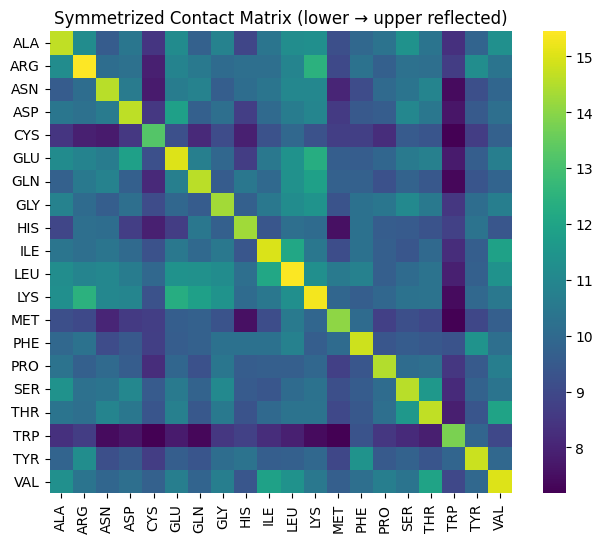

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import pdist, squareform
from collections import defaultdict

# Example residues
residues_protein = [
    'ALA', 'ARG', 'ASN', 'ASP', 'CYS', 'GLU', 'GLN', 'GLY', 'HIS', 'ILE',
    'LEU', 'LYS', 'MET', 'PHE', 'PRO', 'SER', 'THR', 'TRP', 'TYR', 'VAL'
]

# Step 0: conf_matrix = your 25x25 matrix
main_conf = conf_matrix[1:21, 1:21]

# Optional: log-transform
main_conf_log = np.log1p(main_conf)

# Normalize rows
main_conf_norm = normalize(main_conf_log, axis=1, norm='l1')

# with no normalization (straight counts instead of ratios)
# main_conf_norm = main_conf_log

# ----------------- Symmetrize: keep lower triangle, reflect upward -----------------
lower_triangle = np.tril(main_conf_norm)
sym_conf = lower_triangle + lower_triangle.T - np.diag(np.diag(main_conf_norm))

# ----------------- Step 1: compute distance matrix -----------------
dist_matrix = squareform(pdist(sym_conf, metric='cosine'))

# ----------------- Step 2: clustering -----------------
range_k = range(13, 14)  # example range
sil_scores = []
for k in range_k:
    clustering = AgglomerativeClustering(n_clusters=k, metric='precomputed', linkage='average')
    labels = clustering.fit_predict(dist_matrix)
    score = silhouette_score(dist_matrix, labels, metric='precomputed')
    sil_scores.append(score)

best_k = range_k[np.argmax(sil_scores)]
print("Suggested number of groups:", best_k)

final_clustering = AgglomerativeClustering(n_clusters=best_k, metric='precomputed', linkage='average')
final_labels = final_clustering.fit_predict(dist_matrix)

# Group -> residues mapping
groups = defaultdict(list)
for res_idx, grp in enumerate(final_labels, start=1):
    groups[grp].append(residues_protein[res_idx - 1])

print("\nGroup -> residues mapping (lower triangle reflected):")
for grp, residues in groups.items():
    print(f"Group {grp}: {', '.join(residues)}")

# ----------------- Step 3: heatmap -----------------
plt.figure(figsize=(8, 6))
sns.heatmap(sym_conf, cmap="viridis", xticklabels=residues_protein, yticklabels=residues_protein, square=True)
plt.title("Symmetrized Contact Matrix (lower → upper reflected)")
plt.show()


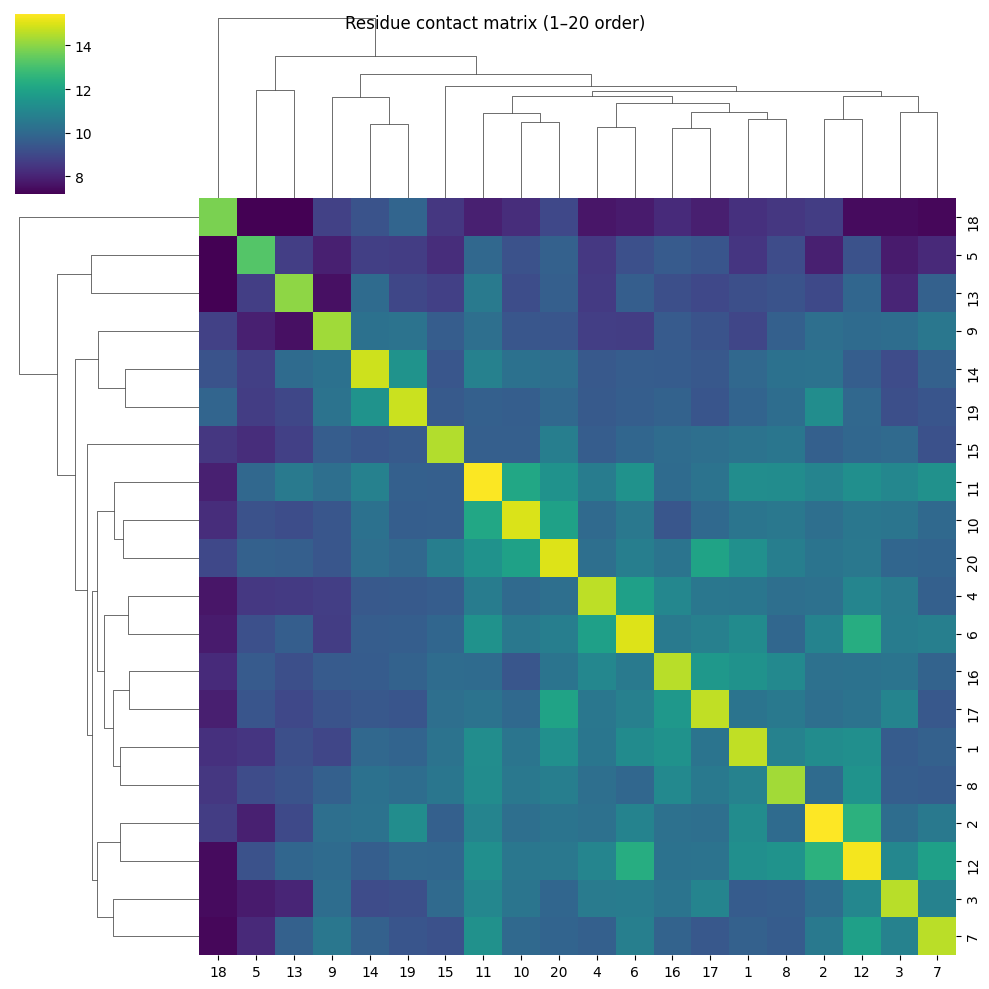

In [115]:
sns.clustermap(
    sym_conf,
    cmap="viridis",
    row_cluster=True,   # 🚫 no row clustering
    col_cluster=True,   # 🚫 no col clustering
    xticklabels=range(1, 21),
    yticklabels=range(1, 21)
)
plt.suptitle("Residue contact matrix (1–20 order)")
plt.show()


2. keep upper triangle and reflect it downwards

Suggested number of groups: 13

Group -> residues mapping (upper triangle reflected):
Group 2: ALA, GLY
Group 0: ARG, GLN, LYS
Group 9: ASN
Group 12: ASP, GLU
Group 10: CYS
Group 7: HIS
Group 1: ILE, LEU, VAL
Group 11: MET
Group 4: PHE
Group 6: PRO
Group 5: SER, THR
Group 8: TRP
Group 3: TYR


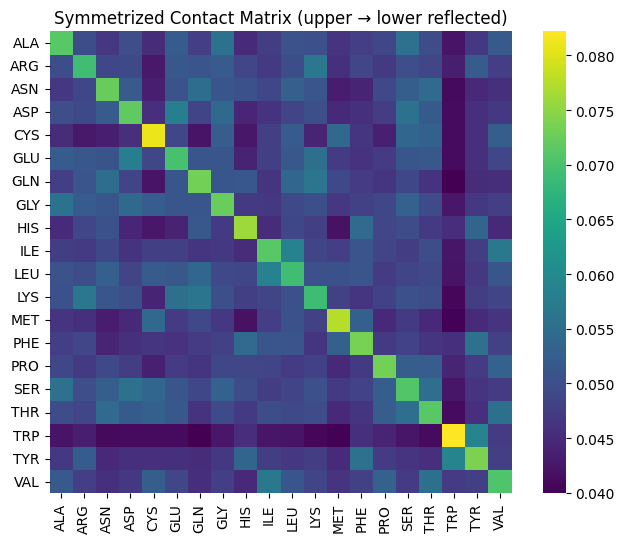

In [111]:
# ----------------- Symmetrize: keep upper triangle, reflect downward -----------------
upper_triangle = np.triu(main_conf_norm)
sym_conf = upper_triangle + upper_triangle.T - np.diag(np.diag(main_conf_norm))

# ----------------- Repeat clustering with this symmetric matrix -----------------
dist_matrix = squareform(pdist(sym_conf, metric='cosine'))

sil_scores = []
for k in range_k:
    clustering = AgglomerativeClustering(n_clusters=k, metric='precomputed', linkage='average')
    labels = clustering.fit_predict(dist_matrix)
    score = silhouette_score(dist_matrix, labels, metric='precomputed')
    sil_scores.append(score)

best_k = range_k[np.argmax(sil_scores)]
print("Suggested number of groups:", best_k)

final_clustering = AgglomerativeClustering(n_clusters=best_k, metric='precomputed', linkage='average')
final_labels = final_clustering.fit_predict(dist_matrix)

groups = defaultdict(list)
for res_idx, grp in enumerate(final_labels, start=1):
    groups[grp].append(residues_protein[res_idx - 1])

print("\nGroup -> residues mapping (upper triangle reflected):")
for grp, residues in groups.items():
    print(f"Group {grp}: {', '.join(residues)}")

plt.figure(figsize=(8, 6))
sns.heatmap(sym_conf, cmap="viridis", xticklabels=residues_protein, yticklabels=residues_protein, square=True)
plt.title("Symmetrized Contact Matrix (upper → lower reflected)")
plt.show()


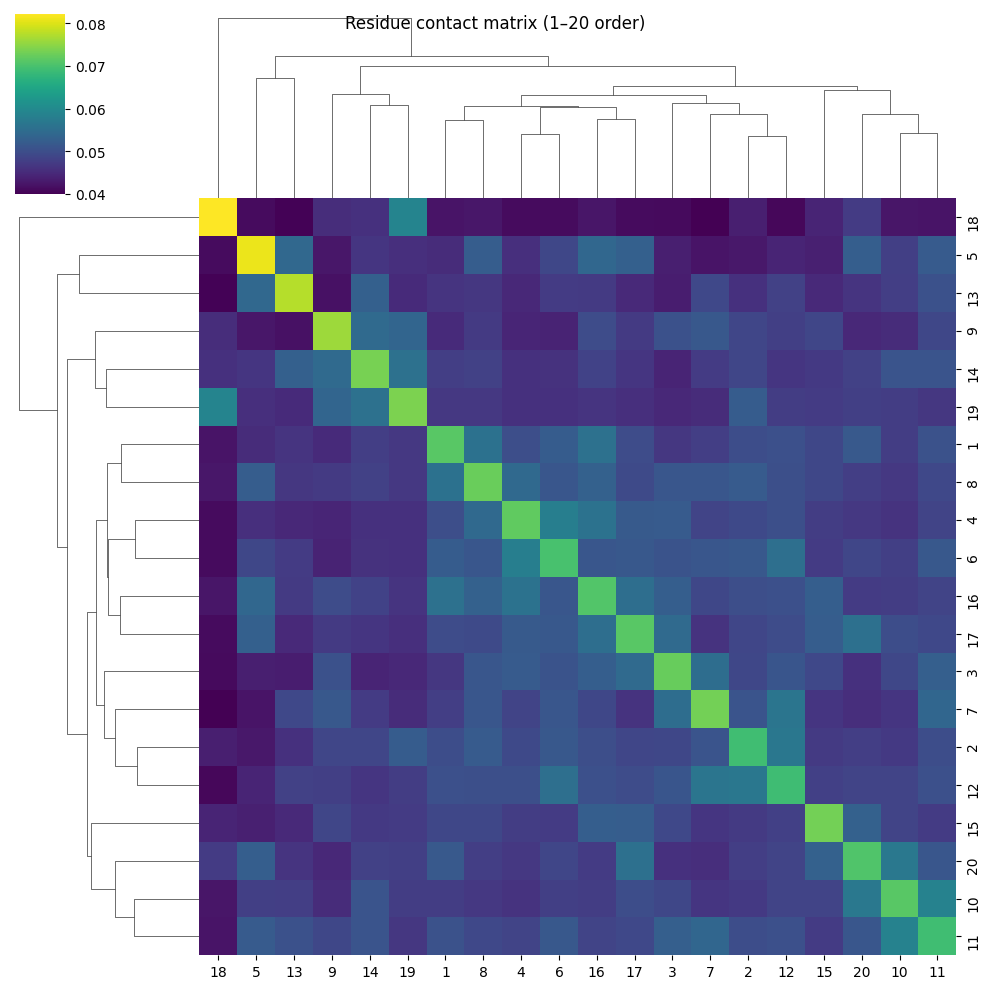

In [112]:
sns.clustermap(
    sym_conf,
    cmap="viridis",
    row_cluster=True,   # 🚫 no row clustering
    col_cluster=True,   # 🚫 no col clustering
    xticklabels=range(1, 21),
    yticklabels=range(1, 21)
)
plt.suptitle("Residue contact matrix (1–20 order)")
plt.show()

masking diagonal out

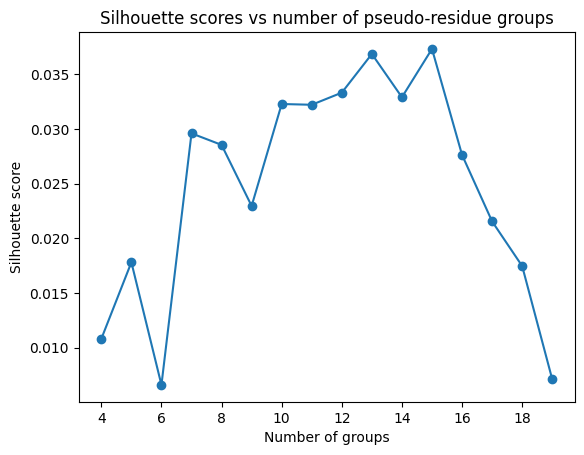

Suggested number of groups: 15

Residue -> pseudo-group mapping:
Residue 1 -> Group 10
Residue 2 -> Group 7
Residue 3 -> Group 0
Residue 4 -> Group 11
Residue 5 -> Group 1
Residue 6 -> Group 12
Residue 7 -> Group 1
Residue 8 -> Group 13
Residue 9 -> Group 9
Residue 10 -> Group 14
Residue 11 -> Group 8
Residue 12 -> Group 4
Residue 13 -> Group 9
Residue 14 -> Group 0
Residue 15 -> Group 1
Residue 16 -> Group 5
Residue 17 -> Group 3
Residue 18 -> Group 4
Residue 19 -> Group 6
Residue 20 -> Group 2


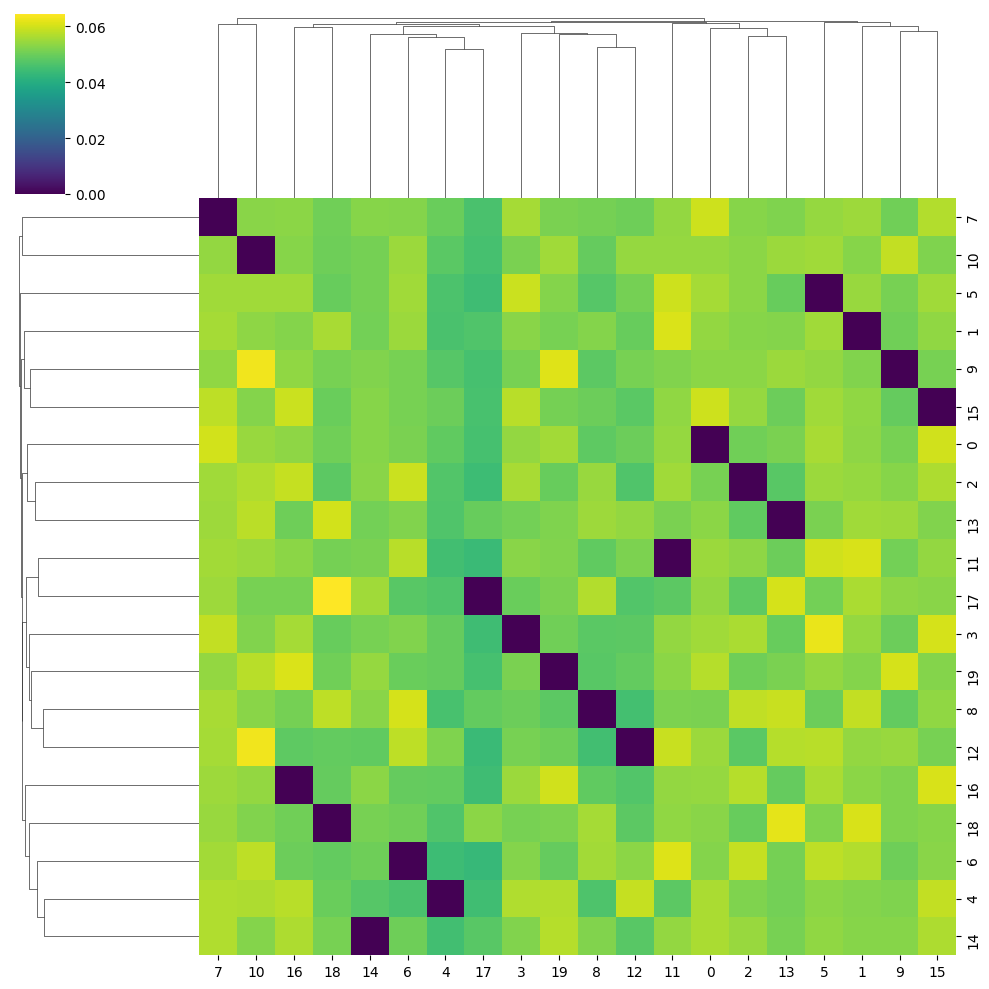

In [108]:
import numpy as np
from sklearn.preprocessing import normalize
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import pdist, squareform
import matplotlib.pyplot as plt
import seaborn as sns

# Step 0: conf_matrix = your 25x25 matrix
main_conf = conf_matrix[1:21, 1:21]

# Optional: log-transform to reduce large magnitude differences
main_conf_log = np.log1p(main_conf)

# mask out diagonal
main_conf_no_diag = main_conf_log.copy()
np.fill_diagonal(main_conf_no_diag, 0)

# Normalize rows so each row sums to 1
main_conf_norm = normalize(main_conf_no_diag, axis=1, norm='l1')

# ----------------- Step 1: compute distance matrix -----------------
# Using correlation distance
dist_matrix = squareform(pdist(main_conf_norm, metric='cosine'))   # use 'cosine' or 'correlation'

# ----------------- Step 2: silhouette analysis for range of clusters -----------------
sil_scores = []
range_k = range(4, 20)

for k in range_k:
    clustering = AgglomerativeClustering(n_clusters=k, metric='precomputed', linkage='average')
    labels = clustering.fit_predict(dist_matrix)
    score = silhouette_score(dist_matrix, labels, metric='precomputed')
    sil_scores.append(score)

# Plot silhouette scores
plt.figure()
plt.plot(range_k, sil_scores, marker='o')
plt.xlabel('Number of groups')
plt.ylabel('Silhouette score')
plt.title('Silhouette scores vs number of pseudo-residue groups')
plt.show()

# ----------------- Step 3: final clustering with best k -----------------
best_k = range_k[np.argmax(sil_scores)]
print("Suggested number of groups:", best_k)

final_clustering = AgglomerativeClustering(n_clusters=best_k, metric='precomputed', linkage='average')
final_labels = final_clustering.fit_predict(dist_matrix)

print("\nResidue -> pseudo-group mapping:")
for cls, grp in enumerate(final_labels, start=1):
    print(f"Residue {cls} -> Group {grp}")

# Optional: clustered heatmap for visualization
sns.clustermap(main_conf_norm, row_cluster=True, col_cluster=True, cmap='viridis', fmt='.3g')
plt.show()
